# 06 · Appendix check: event clustering in the 8-K mention sample
> Run after notebook 04, from inside the `code` folder. Raw inputs are in `data/` (described in notebook 01).
> Research questions: top of notebook 03.

> **Appendix.** This notebook belongs to the appendix of notebook 04. It runs the dependence checks (clustered
> standard errors, daily calendar-time portfolios). Monthly post-announcement portfolios are not used: they would
> describe later returns of the 8-K sample, not of the rename sample, and late-2025 events cannot be followed for
> twelve months.

**Why this notebook?** Notebook 04 finds a mean CAR[−1,+1] of about +2.3% for 1,565 first AI mentions in 8-Ks
(t-test and bootstrap p < 0.001). Those tests assume that the events are **independent**. But AI announcements
**cluster in calendar time**: most fall in 2023–24, after ChatGPT, often many in the same week. When events share
dates, their abnormal returns share the same market-wide shocks (e.g. an "AI rally" week), so the effective
number of independent observations is smaller than 1,565 and the usual standard errors are too small
(Brown & Warner, 1985; Kolari & Pynnönen, 2010). This notebook asks: **does the AI result survive once we allow
for cross-sectional dependence?**

| Step | What happens |
|---|---|
| 0 | Settings |
| 1 | Load the 8-K mention events (notebook 04), CRSP daily data and the daily Fama-French factors (WRDS `ff_all`) |
| 2 | Recompute the CARs with the shared module `buzzword_event_study.py` (identical numbers to notebook 04) |
| 3 | How clustered are the events? Events per week / month and the **intra-cluster correlation** of CARs |
| 4 | (a) **Cross-sectional regressions** with standard errors clustered by event day, week and month, plus a cluster bootstrap |
| 5 | (b) **Daily calendar-time portfolios** of firms in their [−1,+1] window, regressed on CAPM, Fama-French 3 and Carhart 4 factors |
| 6 | How do the AI (and Blockchain) p-values change? Export |

**Calendar-time logic.** Instead of averaging across events, we form one portfolio per calendar period that holds
every firm currently in its event window. Each period counts **once**, however many events it contains, so
clustering cannot inflate the test. The portfolio's excess return is regressed on the factors:
$$R_{p,t} - R_{f,t} = \alpha + \beta\,(R_{m,t}-R_{f,t}) + s\,SMB_t + h\,HML_t + u\,UMD_t + \varepsilon_t$$
α is the average abnormal return per period. Standard errors are Newey-West (HAC). For the daily portfolio of
[−1,+1] windows, 3·α is a rough counterpart of the mean CAR[−1,+1], but the two are **different estimands**
(each day weighted once vs. each event weighted once), so they need not agree.

## Step 0: Settings

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from sklearn import set_config
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

import buzzword_event_study as es

np.random.seed(42)
random_state = 42
rng = np.random.default_rng(random_state)
set_config(transform_output="pandas")  # sklearn transformers return DataFrames
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plt.rc("axes", titlesize=12, labelsize=11)

In [2]:
# ---- paths: run the notebooks from inside the code/ folder ----
base_dir = Path.cwd().parent                                  # project folder (the notebooks run from code/)
data_dir = base_dir / "data"                                  # raw input files (described in notebook 01)
wrds_dir = data_dir / "raw_data" / "wrds"                     # raw WRDS extracts
edgar_dir = data_dir / "raw_data" / "edgar_fts"               # EDGAR full-text search extract
event_dates_dir = data_dir / "event_dates"                    # hand-collected dates + SEC scan results (inputs)
event_dates_out_dir = base_dir / "event_dates"                # event-date table produced by notebook 02
processed_dir = base_dir / "processed"                        # intermediate tables passed between notebooks
output_dir = base_dir / "output"                              # result tables and figures
for folder in [processed_dir, output_dir, event_dates_out_dir, edgar_dir]:
    folder.mkdir(parents=True, exist_ok=True)

# ---- study design ----
study_start_year, study_end_year = 1990, 2025
eligible_exchanges = ["N", "A", "Q"]            # NYSE, NYSE American, Nasdaq
themes = ["Dot-com", "Blockchain", "AI"]         # Dot-com first = reference category in RQ3
theme_colors = {"Dot-com": "#2a78b5", "Blockchain": "#e08a1e", "AI": "#3a9e5f"}
wave_periods = {"Dot-com": (1995, 2002), "Blockchain": (2016, 2020), "AI": (2021, 2025)}
wave_reference_year = {"Dot-com": 1995, "Blockchain": 2017, "AI": 2022}   # Netscape IPO, Bitcoin boom, ChatGPT

# event-study design (estimation window, windows, tests): see buzzword_event_study.py

# ---- extension design ----
themes = ["Blockchain", "AI"]            # Blockchain = reference category in the comparison
extension_waves = {
    "Blockchain": {"terms": ["blockchain", "bitcoin", "cryptocurrency"], "search_start": "2014-01-01",
                   "start": "2016-01-01", "end": "2020-12-31"},
    "AI": {"terms": ["artificial intelligence", "generative AI"], "search_start": "2019-01-01",
           "start": "2021-01-01", "end": "2025-12-31"},
}
novelty_days = 730                       # no buzzword 8-K in the previous 24 months
rename_overlap_days = 90
hits_file = edgar_dir / "edgar_fts_8k_hits.csv.gz"
daily_file = wrds_dir / "crsp_daily_announcement_firms.csv.gz"

# ---- clustering design ----
ff_daily_file = wrds_dir / "ff_factors_daily.csv.gz"          # WRDS ff_all.factors_daily
cluster_levels = {"event day": "D", "event week": "W", "event month": "M"}
factor_models = {"CAPM": ["mktrf"], "FF3": ["mktrf", "smb", "hml"], "Carhart4": ["mktrf", "smb", "hml", "umd"]}
daily_holding_windows = {"[-1,+1]": (-1, 1)}
hac_lags = {"daily": 5}
min_portfolio_firms = {"all periods (>= 1 firm)": 1, "periods with >= 5 firms": 5}   # main = every period with a firm

## Step 1: Load the inputs
* `processed/announcement_events.csv` (notebook 04): eligible 8-K mention events; the main sample excludes
  blank-check shells and firms that also renamed.
* CRSP daily data of the announcing firms (notebook 04).
* Daily Fama-French factors from WRDS (`ff_all.factors_daily`): market excess return, SMB, HML, momentum (UMD)
  and the risk-free rate (described in notebook 01).

In [3]:
announcements = pd.read_csv(processed_dir / "announcement_events.csv", parse_dates=["event_date", "effective_date"])
main = announcements[announcements["in_main_sample"] == 1].reset_index(drop=True)
daily = es.load_daily(daily_file)
market = es.load_market(wrds_dir / "crsp_daily_market_index.csv.gz")
ff_daily = pd.read_csv(ff_daily_file, parse_dates=["date"])
for name, table in {"main events": main, "daily": daily, "ff daily": ff_daily}.items():
    print(f"  {name:<12} {table.shape[0]:>9,} rows x {table.shape[1]} cols")
ff_daily.describe().round(4)

  main events      1,735 rows x 24 cols
  daily          578,759 rows x 12 cols
  ff daily         9,738 rows x 6 cols


,date,mktrf,smb,hml,rf,umd
count,9738,9738.0000,9738.0000,9738.0000,9738.0000,9738.0000
mean,2007-04-23 20:31:12.088724,0.0004,0.0000,0.0001,0.0001,0.0002
min,1988-01-04 00:00:00,-0.1201,-0.0449,-0.0503,0.0000,-0.1439
25%,1997-08-18 06:00:00,-0.0043,-0.0035,-0.0029,0.0000,-0.0032
50%,2007-04-24 12:00:00,0.0007,0.0001,0.0000,0.0001,0.0006
75%,2016-12-20 18:00:00,0.0056,0.0034,0.0029,0.0002,0.0043
max,2026-08-31 00:00:00,0.1136,0.0545,0.0673,0.0004,0.0712
std,NaN,0.0112,0.0060,0.0069,0.0001,0.0093


## Step 2: CARs (shared module, same numbers as notebook 04)

In [4]:
abnormal, estimates, _ = es.compute_abnormal_returns(main, daily, market, "market_model", "event_date")
cars = es.compute_cars(abnormal, estimates, main, keep_columns=["event_id", "permno", "theme", "event_date", "new_name"])
crsp_controls = ["log_market_cap", "price", "pre_event_return", "pre_event_volatility"]
cars = cars.merge(es.build_crsp_characteristics(main, daily, market), on="event_id", how="left")
cars["price"] = np.log(cars["price"])            # log transform of a skewed variable (Tutorial 4)
for label, code in cluster_levels.items():
    cars[label] = cars["event_date"].dt.to_period(code).astype(str)
baseline = es.summarise_event_study(cars, {t: (lambda d, t=t: d["theme"] == t) for t in themes},
                                    ["car_m1_p1", "car_m5_p5", "cav_m1_p1"])
baseline[["sample", "measure", "n", "mean", "median", "t_pvalue", "sign_pvalue", "wilcoxon_pvalue",
          "bmp_pvalue", "boot_pvalue"]].round(4)

,sample,measure,n,mean,median,t_pvalue,sign_pvalue,wilcoxon_pvalue,bmp_pvalue,boot_pvalue
0,Blockchain,car_m1_p1,151,0.0546,-0.0089,0.1669,0.3288,0.2863,0.5556,0.1371
1,Blockchain,car_m5_p5,150,0.0550,-0.0084,0.2367,0.3692,0.1977,0.5145,0.2182
2,Blockchain,cav_m1_p1,146,2.0715,1.2415,0.0000,0.0000,0.0000,NaN,0.0000
3,AI,car_m1_p1,1565,0.0230,0.0015,0.0000,0.3628,0.1012,0.0592,0.0000
4,AI,car_m5_p5,1540,0.0252,0.0023,0.0007,0.4004,0.4191,0.6005,0.0012
5,AI,cav_m1_p1,1496,2.0616,1.5298,0.0000,0.0000,0.0000,NaN,0.0000


## Step 3: How clustered are the events?
* **Concentration:** number of distinct event days / weeks / months, the largest number of events in one week or
  month, and the share of events in the busiest 10% of months.
* **Intra-cluster correlation (ICC)** of CAR[−1,+1] within event weeks and months, from a one-way ANOVA:
  $$ICC = \frac{MS_{between} - MS_{within}}{MS_{between} + (k_0 - 1)\,MS_{within}}$$
  with $k_0$ the (adjusted) average cluster size. The variance of a mean of *n* events grows by the **design
  effect** $1 + (\bar m - 1)\,ICC$ ($\bar m$ = average events per cluster). Even a small positive ICC matters when
  clusters are large.

In [5]:
def intra_cluster_correlation(values, clusters):
    """
    One-way ANOVA estimate of the intra-cluster correlation.

    Parameters
    ----------
    values : pandas.Series
        Event outcomes (e.g. CAR[-1,+1]).
    clusters : pandas.Series
        Cluster label of each event (e.g. event week).

    Returns
    -------
    tuple of float
        (ICC, design effect, average cluster size)
    """
    data = pd.DataFrame({"y": values, "g": clusters}).dropna()
    sizes = data.groupby("g")["y"].size()
    n, k = len(data), len(sizes)
    means = data.groupby("g")["y"].transform("mean")
    ms_between = (sizes * (data.groupby("g")["y"].mean() - data["y"].mean()) ** 2).sum() / (k - 1)
    ms_within = ((data["y"] - means) ** 2).sum() / (n - k)
    k0 = (n - (sizes ** 2).sum() / n) / (k - 1)
    icc = (ms_between - ms_within) / (ms_between + (k0 - 1) * ms_within)
    return icc, 1 + (sizes.mean() - 1) * icc, sizes.mean()


rows = []
for theme in themes:
    data = cars[(cars["theme"] == theme)].dropna(subset=["car_m1_p1"])
    row = {"wave": theme, "events": len(data)}
    for label in cluster_levels:
        counts = data.groupby(label).size()
        row[f"distinct {label}s"] = len(counts)
        row[f"max events per {label}"] = counts.max()
    month_counts = data.groupby("event month").size().sort_values(ascending=False)
    row["share in busiest 10% of months"] = month_counts.head(max(1, int(np.ceil(len(month_counts) * 0.1)))).sum() / len(data)
    for label in ["event week", "event month"]:
        icc, design_effect, _ = intra_cluster_correlation(data["car_m1_p1"], data[label])
        row[f"ICC ({label})"], row[f"design effect ({label})"] = icc, design_effect
    rows.append(row)
clustering_diagnostics = pd.DataFrame(rows).set_index("wave").T
clustering_diagnostics.round(4)

wave,Blockchain,AI
events,151.0000,1565.0000
distinct event days,138.0000,750.0000
max events per event day,3.0000,11.0000
distinct event weeks,99.0000,252.0000
max events per event week,4.0000,27.0000
distinct event months,46.0000,60.0000
max events per event month,11.0000,70.0000
share in busiest 10% of months,0.2980,0.2115
ICC (event week),-0.4805,0.0159
design effect (event week),0.7476,1.0826


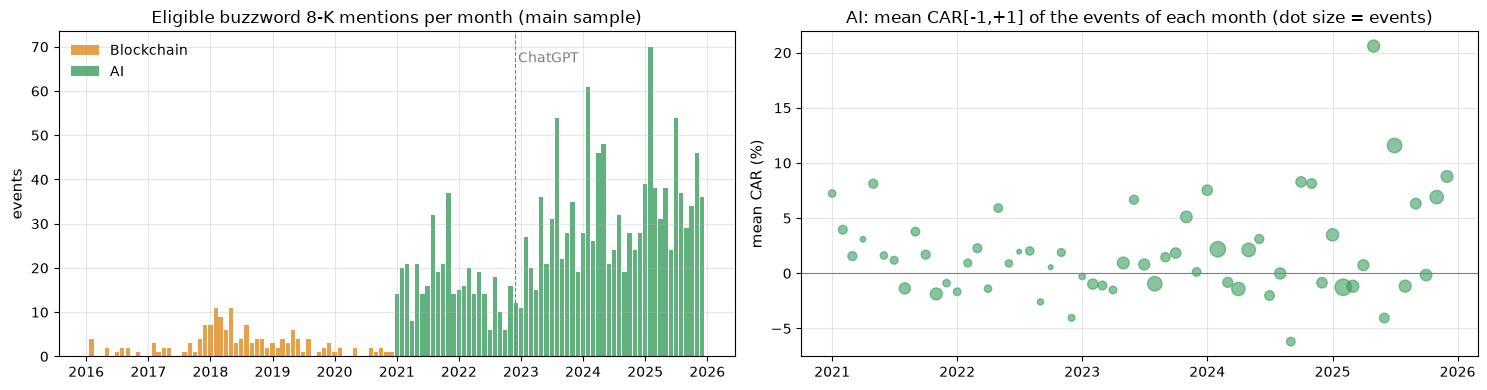

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
per_month = cars.assign(month=cars["event_date"].dt.to_period("M").dt.to_timestamp()) \
    .groupby(["month", "theme"]).size().unstack().reindex(columns=themes).fillna(0)
for theme in themes:
    axes[0].bar(per_month.index, per_month[theme], width=25, color=theme_colors[theme], alpha=0.8, label=theme)
axes[0].axvline(pd.Timestamp("2022-11-30"), color="grey", ls="--", lw=0.8)
axes[0].text(pd.Timestamp("2022-12-15"), per_month.values.max() * 0.95, "ChatGPT", color="grey")
axes[0].set(title="Eligible buzzword 8-K mentions per month (main sample)", ylabel="events")
axes[0].legend(frameon=False)
ai_months = cars[cars["theme"] == "AI"].groupby("event month").agg(events=("car_m1_p1", "size"), mean_car=("car_m1_p1", "mean"))
ai_months.index = pd.PeriodIndex(ai_months.index, freq="M").to_timestamp()
axes[1].scatter(ai_months.index, ai_months["mean_car"] * 100, s=ai_months["events"] * 2, color=theme_colors["AI"], alpha=0.6)
axes[1].axhline(0, color="grey", lw=0.8)
axes[1].set(title="AI: mean CAR[-1,+1] of the events of each month (dot size = events)", ylabel="mean CAR (%)")
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(output_dir / "clu_events_per_month.png", dpi=150)
plt.show()

## Step 4 (a): Cross-sectional regressions with clustered standard errors
**Mean test as a regression.** Regressing CAR on a constant reproduces the cross-sectional t-test; only the
covariance estimator changes:
* `iid`: the classical t-test of notebook 04;
* `HC3`: heteroskedasticity-robust;
* **clustered by event day / week / month** (Liang-Zeger), which allows any correlation between events in the
  same calendar period;
* **cluster bootstrap**: resample whole event months with replacement (10,000 draws), which keeps the
  within-month dependence in every draw.

The same estimators are applied to the BMP-standardised CAR and to the **AI − Blockchain** comparison (OLS with an
AI dummy, with and without CRSP controls, Tutorial 4 preprocessing pipeline).

In [7]:
def fit_with_covariance(y, design, cov_name, clusters=None):
    """
    Fit OLS and return the results with the chosen covariance estimator.

    Parameters
    ----------
    y : pandas.Series
    design : pandas.DataFrame
        Regressors incl. the constant.
    cov_name : {"iid", "HC3", "cluster"}
    clusters : pandas.Series, optional
        Cluster labels (only for ``cluster``).

    Returns
    -------
    statsmodels.regression.linear_model.RegressionResultsWrapper
    """
    model = sm.OLS(y.astype(float), design.astype(float))
    if cov_name == "iid":
        return model.fit()
    if cov_name == "HC3":
        return model.fit(cov_type="HC3")
    codes = pd.factorize(clusters)[0]
    return model.fit(cov_type="cluster", cov_kwds={"groups": codes, "use_correction": True}, use_t=True)


def cluster_bootstrap_mean(values, clusters, n_draws=es.N_BOOTSTRAP):
    """
    Cluster (block) bootstrap of the mean: resample whole clusters with replacement.

    Parameters
    ----------
    values : pandas.Series
    clusters : pandas.Series
    n_draws : int

    Returns
    -------
    tuple of float
        (lower bound, upper bound, two-sided p-value of "mean = 0")
    """
    data = pd.DataFrame({"y": values, "g": clusters}).dropna()
    sums = data.groupby("g")["y"].agg(["sum", "size"])
    picks = rng.integers(0, len(sums), size=(n_draws, len(sums)))
    draws = sums["sum"].to_numpy()[picks].sum(axis=1) / sums["size"].to_numpy()[picks].sum(axis=1)
    observed = data["y"].mean()
    p_value = (np.abs(draws - observed) >= abs(observed)).mean()
    return np.percentile(draws, 2.5), np.percentile(draws, 97.5), p_value


def clustered_mean_tests(cars, outcomes=("car_m1_p1", "car_m5_p5", "scar_m1_p1", "cav_m1_p1")):
    """
    Test "mean outcome = 0" per wave under different covariance estimators.

    Parameters
    ----------
    cars : pandas.DataFrame
    outcomes : tuple of str

    Returns
    -------
    pandas.DataFrame
        One row per wave, outcome and estimator: mean, standard error, p-value and number of clusters.
    """
    rows = []
    for theme in themes:
        for outcome in outcomes:
            data = cars[cars["theme"] == theme].dropna(subset=[outcome]).reset_index(drop=True)
            y, design = data[outcome], pd.DataFrame({"const": np.ones(len(data))})
            for estimator in ["iid", "HC3"] + list(cluster_levels):
                cov_name = "cluster" if estimator in cluster_levels else estimator
                results = fit_with_covariance(y, design, cov_name, data[estimator] if cov_name == "cluster" else None)
                rows.append({"wave": theme, "outcome": outcome, "estimator": estimator if cov_name != "cluster"
                             else f"clustered by {estimator}", "n": len(data), "mean": results.params["const"],
                             "se": results.bse["const"], "p_value": results.pvalues["const"],
                             "clusters": data[estimator].nunique() if cov_name == "cluster" else len(data)})
            low, high, p_value = cluster_bootstrap_mean(y, data["event month"])
            rows.append({"wave": theme, "outcome": outcome, "estimator": "cluster bootstrap (event month)",
                         "n": len(data), "mean": y.mean(), "ci_low": low, "ci_high": high, "p_value": p_value,
                         "clusters": data["event month"].nunique()})
    return pd.DataFrame(rows)


clustered_tests = clustered_mean_tests(cars)
clustered_tests.pivot_table(index=["outcome", "estimator"], columns="wave", values="p_value", sort=False).round(4)

wave                                        Blockchain      AI
outcome    estimator                                          
car_m1_p1  iid                                  0.1669  0.0000
           HC3                                  0.1662  0.0000
           clustered by event day               0.1679  0.0000
           clustered by event week              0.2454  0.0000
           clustered by event month             0.2706  0.0021
           cluster bootstrap (event month)      0.2622  0.0016
car_m5_p5  iid                                  0.2367  0.0007
           HC3                                  0.2363  0.0007
           clustered by event day               0.2384  0.0008
           clustered by event week              0.2219  0.0018
           clustered by event month             0.2194  0.0177
           cluster bootstrap (event month)      0.2023  0.0128
scar_m1_p1 iid                                  0.5556  0.0592
           HC3                                  0.5561  0.0591
           clustered by event day               0.5590  0.0617
           clustered by event week              0.5763  0.0674
           clustered by event month             0.6476  0.1196
           cluster bootstrap (event month)      0.6464  0.1063
cav_m1_p1  iid                                  0.0000  0.0000
           HC3                                  0.0000  0.0000
           clustered by event day               0.0000  0.0000
           clustered by event week              0.0000  0.0000
           clustered by event month             0.0000  0.0000
           cluster bootstrap (event month)      0.0000  0.0000

In [8]:
def clustered_wave_regressions(cars, outcomes=("car_m1_p1", "car_m5_p5")):
    """
    AI - Blockchain difference (AI dummy, Blockchain = reference) under different covariance estimators.

    Parameters
    ----------
    cars : pandas.DataFrame
    outcomes : tuple of str

    Returns
    -------
    pandas.DataFrame
    """
    rows = []
    for outcome in outcomes:
        data = cars.dropna(subset=[outcome]).reset_index(drop=True)
        for label, controls in [("(1) AI dummy only", []), ("(2) + CRSP controls", crsp_controls)]:
            transformers = [("theme", OneHotEncoder(categories=[themes], drop="first", sparse_output=False), ["theme"])]
            if controls:
                transformers.append(("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), controls))
            design = sm.add_constant(ColumnTransformer(transformers, verbose_feature_names_out=False).fit_transform(data))
            for estimator in ["HC3"] + list(cluster_levels):
                cov_name = "cluster" if estimator in cluster_levels else estimator
                results = fit_with_covariance(data[outcome], design, cov_name, data[estimator] if cov_name == "cluster" else None)
                rows.append({"outcome": outcome, "model": label, "estimator": estimator if cov_name != "cluster"
                             else f"clustered by {estimator}", "coef_AI": results.params["theme_AI"],
                             "se": results.bse["theme_AI"], "p_value": results.pvalues["theme_AI"], "n_obs": int(results.nobs)})
    return pd.DataFrame(rows)


wave_regressions_clustered = clustered_wave_regressions(cars)
wave_regressions_clustered.round(4)

,outcome,model,estimator,coef_AI,se,p_value,n_obs
0,car_m1_p1,(1) AI dummy only,HC3,-0.0316,0.0398,0.4275,1716
1,car_m1_p1,(1) AI dummy only,clustered by event day,-0.0316,0.0396,0.4259,1716
2,car_m1_p1,(1) AI dummy only,clustered by event week,-0.0316,0.0469,0.5010,1716
3,car_m1_p1,(1) AI dummy only,clustered by event month,-0.0316,0.0492,0.5222,1716
4,car_m1_p1,(2) + CRSP controls,HC3,-0.0259,0.0401,0.5178,1716
5,car_m1_p1,(2) + CRSP controls,clustered by event day,-0.0259,0.0400,0.5167,1716
6,car_m1_p1,(2) + CRSP controls,clustered by event week,-0.0259,0.0471,0.5827,1716
7,car_m1_p1,(2) + CRSP controls,clustered by event month,-0.0259,0.0489,0.5970,1716
8,car_m5_p5,(1) AI dummy only,HC3,-0.0298,0.0471,0.5263,1690
9,car_m5_p5,(1) AI dummy only,clustered by event day,-0.0298,0.0469,0.5254,1690


## Step 5 (b): Daily calendar-time portfolios
For every trading day, the equal-weighted portfolio holds the firms for which that day lies in their [−1,+1]
event window (day 0 on the market calendar, as in the shared module). Every day with at least one firm counts
(Jaffe-Mandelker convention); as a robustness check, only days with at least 5 firms (less noisy portfolios).

In [9]:
def build_daily_portfolio(events, daily, market, window):
    """
    Equal-weighted daily calendar-time portfolio of firms inside their event window.

    Parameters
    ----------
    events : pandas.DataFrame
        Events of one wave (``event_id``, ``permno``, ``event_date``).
    daily, market : pandas.DataFrame
        CRSP daily data and the market calendar (:func:`es.load_market`).
    window : tuple of int
        Event window in trading sessions, e.g. (-1, 1).

    Returns
    -------
    pandas.DataFrame
        One row per trading day: ``portfolio_return`` and ``firms``.
    """
    data = daily.merge(market[["date", "session"]], on="date")
    groups = dict(tuple(data.groupby("permno")))
    frames = []
    for event in events.itertuples():
        day0 = es.day0_session(event.event_date, market)
        firm = groups.get(event.permno)
        if day0 is not None and firm is not None:
            firm = es.locate_event_window(firm, day0)
            frames.append(firm.loc[firm["relative_day"].between(*window), ["date", "permno", "dlyret"]])
    holdings = pd.concat(frames).dropna(subset=["dlyret"]).drop_duplicates(["date", "permno"])
    return holdings.groupby("date").agg(portfolio_return=("dlyret", "mean"), firms=("permno", "nunique")).reset_index()


def fit_factor_models(portfolio, factors, return_column, scale, min_firms=1):
    """
    Regress the daily portfolio's excess return on CAPM, FF3 and Carhart factors with Newey-West errors.

    Parameters
    ----------
    portfolio : pandas.DataFrame
    factors : pandas.DataFrame
        Daily Fama-French factors with ``rf``.
    return_column : str
    scale : int
        Multiplier for the implied cumulative abnormal return (window length in days).
    min_firms : int
        Minimum number of firms for a day to enter the regression.

    Returns
    -------
    list of dict
        Empty when fewer than 12 days are left.
    """
    data = portfolio[portfolio["firms"] >= min_firms].merge(factors, on="date").dropna(subset=[return_column])
    if len(data) < 12:
        return []
    excess = data[return_column] - data["rf"]
    rows = []
    for model, columns in factor_models.items():
        results = sm.OLS(excess, sm.add_constant(data[columns])).fit(cov_type="HAC", cov_kwds={"maxlags": hac_lags["daily"]})
        rows.append({"model": model, "alpha": results.params["const"], "alpha_se": results.bse["const"],
                     "p_value": results.pvalues["const"], "implied_car": results.params["const"] * scale,
                     "periods": int(results.nobs), "avg_firms": data["firms"].mean(), "r_squared": results.rsquared})
    return rows


calendar_rows = []
for theme in themes:
    events = cars[cars["theme"] == theme]
    for period_rule, min_firms in min_portfolio_firms.items():
        for label, window in daily_holding_windows.items():
            portfolio = build_daily_portfolio(events, daily, market, window)
            for row in fit_factor_models(portfolio, ff_daily, "portfolio_return", window[1] - window[0] + 1, min_firms):
                calendar_rows.append({"wave": theme, "periods_used": period_rule, "frequency": "daily", "holding": label,
                                      "weighting": "EW", **row})
calendar_time = pd.DataFrame(calendar_rows)
main_rule = list(min_portfolio_firms)[0]
calendar_time.round(4)

,wave,periods_used,frequency,holding,weighting,model,alpha,alpha_se,p_value,implied_car,periods,avg_firms,r_squared
0,Blockchain,all periods (>= 1 firm),daily,"[-1,+1]",EW,CAPM,0.0178,0.0121,0.1409,0.0535,348,1.3075,0.0084
1,Blockchain,all periods (>= 1 firm),daily,"[-1,+1]",EW,FF3,0.0181,0.0120,0.1311,0.0542,348,1.3075,0.0278
2,Blockchain,all periods (>= 1 firm),daily,"[-1,+1]",EW,Carhart4,0.0180,0.0119,0.1308,0.0541,348,1.3075,0.0285
3,AI,all periods (>= 1 firm),daily,"[-1,+1]",EW,CAPM,0.0080,0.0024,0.0007,0.0240,1129,4.1816,0.0349
4,AI,all periods (>= 1 firm),daily,"[-1,+1]",EW,FF3,0.0082,0.0024,0.0005,0.0246,1129,4.1816,0.0441
5,AI,all periods (>= 1 firm),daily,"[-1,+1]",EW,Carhart4,0.0083,0.0024,0.0004,0.0249,1129,4.1816,0.0463
6,AI,periods with >= 5 firms,daily,"[-1,+1]",EW,CAPM,0.0034,0.0022,0.1194,0.0103,381,7.7900,0.0641
7,AI,periods with >= 5 firms,daily,"[-1,+1]",EW,FF3,0.0035,0.0022,0.1045,0.0105,381,7.7900,0.0716
8,AI,periods with >= 5 firms,daily,"[-1,+1]",EW,Carhart4,0.0034,0.0021,0.1135,0.0101,381,7.7900,0.0746


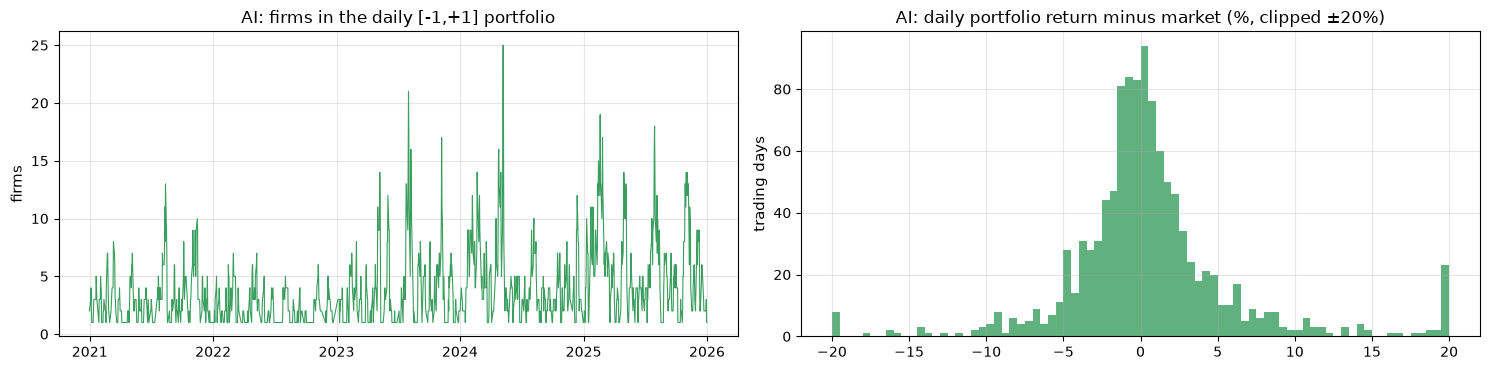

In [10]:
# Daily [-1,+1] portfolio of AI firms: how many firms per day, and which days dominate?
ai_portfolio = build_daily_portfolio(cars[cars["theme"] == "AI"], daily, market, (-1, 1))
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
axes[0].plot(ai_portfolio["date"], ai_portfolio["firms"], color=theme_colors["AI"], lw=0.8)
axes[0].set(title="AI: firms in the daily [-1,+1] portfolio", ylabel="firms")
excess = ai_portfolio.merge(ff_daily, on="date")
axes[1].hist((excess["portfolio_return"] - excess["rf"] - excess["mktrf"]).clip(-0.2, 0.2) * 100, bins=80,
             color=theme_colors["AI"], alpha=0.8)
axes[1].set(title="AI: daily portfolio return minus market (%, clipped ±20%)", ylabel="trading days")
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(output_dir / "clu_ai_daily_portfolio.png", dpi=150)
plt.show()

## Step 6: How do the p-values change?
One table per wave for CAR[−1,+1]: the event-level tests of notebook 04, the clustered cross-sectional tests and
the daily calendar-time portfolio α (FF3 and Carhart).

In [11]:
def p_value_overview(theme):
    """
    Collect the CAR[-1,+1] evidence for one wave from all methods.

    Parameters
    ----------
    theme : str

    Returns
    -------
    pandas.DataFrame
        ``method``, ``estimate`` (mean CAR or implied CAR), ``p_value`` and ``units`` (independent observations).
    """
    base = baseline[(baseline["sample"] == theme) & (baseline["measure"] == "car_m1_p1")].iloc[0]
    rows = [{"method": "event-level t-test (notebook 04)", "estimate": base["mean"], "p_value": base["t_pvalue"], "units": base["n"]},
            {"method": "event-level bootstrap (notebook 04)", "estimate": base["mean"], "p_value": base["boot_pvalue"], "units": base["n"]},
            {"method": "sign test (median)", "estimate": base["median"], "p_value": base["sign_pvalue"], "units": base["n"]},
            {"method": "BMP standardised test", "estimate": base["mean"], "p_value": base["bmp_pvalue"], "units": base["n"]}]
    tests = clustered_tests[(clustered_tests["wave"] == theme) & (clustered_tests["outcome"] == "car_m1_p1")]
    for row in tests.itertuples():
        if row.estimator != "iid":
            rows.append({"method": f"OLS, {row.estimator}", "estimate": row.mean, "p_value": row.p_value, "units": row.clusters})
    ct = calendar_time[calendar_time["wave"] == theme]
    for (rule, model), label in {(main_rule, "FF3"): "calendar-time daily [-1,+1], FF3 (3·alpha)",
                                 (main_rule, "Carhart4"): "calendar-time daily [-1,+1], Carhart (3·alpha)",
                                 ("periods with >= 5 firms", "FF3"): "calendar-time daily [-1,+1], FF3, days with >= 5 firms"}.items():
        row = ct[(ct["periods_used"] == rule) & (ct["model"] == model)]
        if len(row):
            rows.append({"method": label, "estimate": row["implied_car"].iloc[0], "p_value": row["p_value"].iloc[0],
                         "units": row["periods"].iloc[0]})
    return pd.DataFrame(rows).assign(wave=theme)


p_values = pd.concat([p_value_overview(theme) for theme in themes], ignore_index=True)
p_values.pivot_table(index="method", columns="wave", values=["estimate", "p_value", "units"], sort=False).round(4)

estimate            p_value              units        
wave                                               Blockchain      AI Blockchain      AI Blockchain      AI
method                                                                                                     
event-level t-test (notebook 04)                       0.0546  0.0230     0.1669  0.0000      151.0  1565.0
event-level bootstrap (notebook 04)                    0.0546  0.0230     0.1371  0.0000      151.0  1565.0
sign test (median)                                    -0.0089  0.0015     0.3288  0.3628      151.0  1565.0
BMP standardised test                                  0.0546  0.0230     0.5556  0.0592      151.0  1565.0
OLS, HC3                                               0.0546  0.0230     0.1662  0.0000      151.0  1565.0
OLS, clustered by event day                            0.0546  0.0230     0.1679  0.0000      138.0   750.0
OLS, clustered by event week                           0.0546  0.0230     0.2454  0.0000       99.0   252.0
OLS, clustered by event month                          0.0546  0.0230     0.2706  0.0021       46.0    60.0
OLS, cluster bootstrap (event month)                   0.0546  0.0230     0.2622  0.0016       46.0    60.0
calendar-time daily [-1,+1], FF3 (3·alpha)             0.0542  0.0246     0.1311  0.0005      348.0  1129.0
calendar-time daily [-1,+1], Carhart (3·alpha)         0.0541  0.0249     0.1308  0.0004      348.0  1129.0
calendar-time daily [-1,+1], FF3, days with >= ...        NaN  0.0105        NaN  0.1045        NaN   381.0

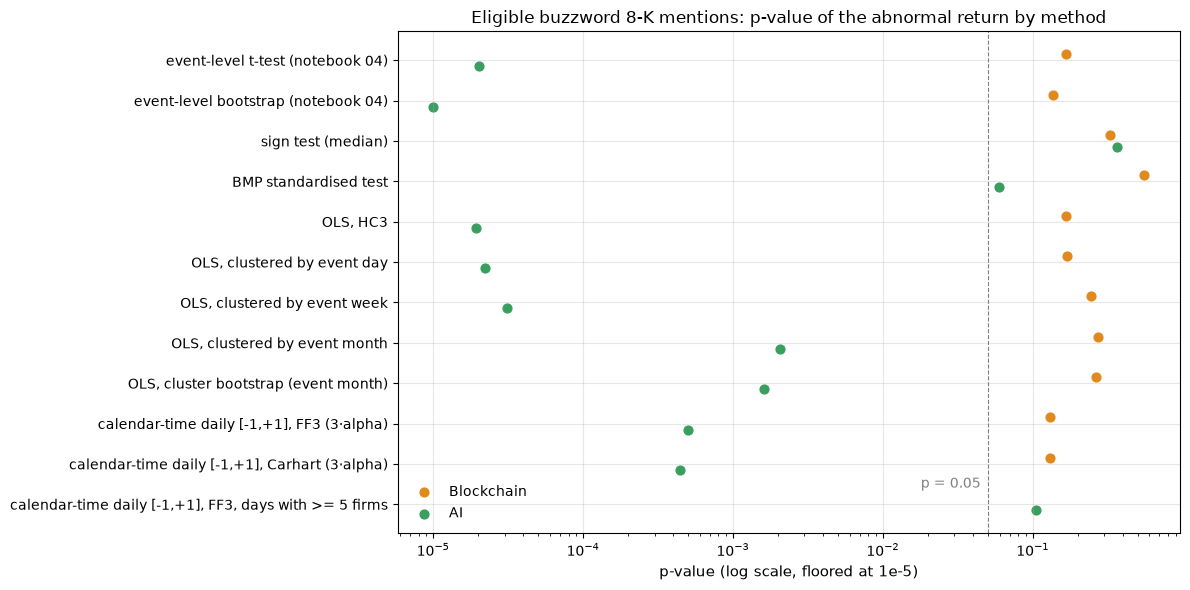

In [12]:
fig, ax = plt.subplots(figsize=(12, 6))
methods = p_values["method"].drop_duplicates().tolist()
for offset, theme in zip([-0.15, 0.15], themes):
    data = p_values[p_values["wave"] == theme].set_index("method").reindex(methods)
    ax.scatter(data["p_value"].clip(lower=1e-5), np.arange(len(methods)) + offset, color=theme_colors[theme], label=theme, s=40)
ax.axvline(0.05, color="grey", ls="--", lw=0.8)
ax.text(0.045, len(methods) - 1.5, "p = 0.05", color="grey", ha="right", va="center")   # left of the line, between the last two rows
ax.set_xscale("log")
ax.set_yticks(range(len(methods)), methods)
ax.invert_yaxis()
ax.set(title="Eligible buzzword 8-K mentions: p-value of the abnormal return by method", xlabel="p-value (log scale, floored at 1e-5)")
ax.legend(frameon=False, loc="lower left")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(output_dir / "clu_pvalues_by_method.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
with pd.ExcelWriter(output_dir / "event_clustering_results.xlsx") as writer:
    for sheet, table in {"pvalues_by_method": p_values, "baseline_event_study": baseline,
                         "clustering_diagnostics": clustering_diagnostics.reset_index(names="statistic"),
                         "clustered_mean_tests": clustered_tests, "clustered_ai_vs_blockchain": wave_regressions_clustered,
                         "calendar_time_portfolios": calendar_time, "event_level": cars}.items():
        table.to_excel(writer, sheet_name=sheet[:31], index=False)
print("results written to", output_dir / "event_clustering_results.xlsx")

results written to /Users/chunhanliao/Documents/FS_MADS/1_IntroDA/Group Project/IDA_Group7_whats_in_a_buzzword_submission/output/event_clustering_results.xlsx


## Summary (numbers from the run above)
**How clustered are the AI 8-K events?** The 1,565 AI events fall on 750 trading days, in 252 weeks and 60
months; up to 27 share one week and 70 one month. The intra-cluster correlation of CAR[−1,+1] is small but
positive (0.016 within weeks, 0.012 within months), which with about 26 events per month raises the variance of
the mean by a design effect of about 1.3. Blockchain events show no positive within-cluster correlation.

**Dependence-aware tests.** The AI mean CAR[−1,+1] of +2.3% stays significant when standard errors are clustered
by event month (p = 0.002, 60 clusters) and with a cluster bootstrap (p = 0.002). In the daily calendar-time
portfolio, where each day counts once, 3·α = +2.5% (FF3, p = 0.0005). But on days with at least 5 AI announcers
it is only +1.0% (p = 0.10), and the median-based sign test (p = 0.36) and the BMP test (p = 0.06) are not
significant. Blockchain is not significant under any method; the AI − Blockchain difference is not significant
under any estimator (p = 0.43–0.67).

**Bottom line for the appendix:** a small mean reaction to eligible AI 8-K mentions, robust to calendar
clustering of the mean, but driven by a minority of firms and silent on the median.